# 02 — Prétraitement, Découpage en Patchs et Illumination Retinex
**Projet NightVision Gen — Modèle de diffusion conditionnelle**

Ce notebook implémente la préparation scientifique des données :
1. **Extraction de patchs 128 × 128** : réalisée *après* découpage des partitions pour garantir l'absence de fuite d'information.
2. **Estimation de la carte d'illumination Retinex** :
   $$L(x, y) = \max(R(x, y), G(x, y), B(x, y))$$
   suivi d'un lissage gaussien pour isoler la composante d'illumination basse fréquence.
3. **Reconstruction pleine image sans coutures** via fenêtrage de Hann pondéré.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append(str(Path("..").resolve() / "src"))

from nightvision.illumination.retinex import RetinexEstimator, compute_illumination_map
from nightvision.data.patch_extractor import PatchExtractor
from nightvision.data.dataset import SyntheticPairDataset

print("✅ Modules Retinex et PatchExtractor importés.")

✅ Modules Retinex et PatchExtractor importés.


### 1. Test du Calcul Retinex sur une Image

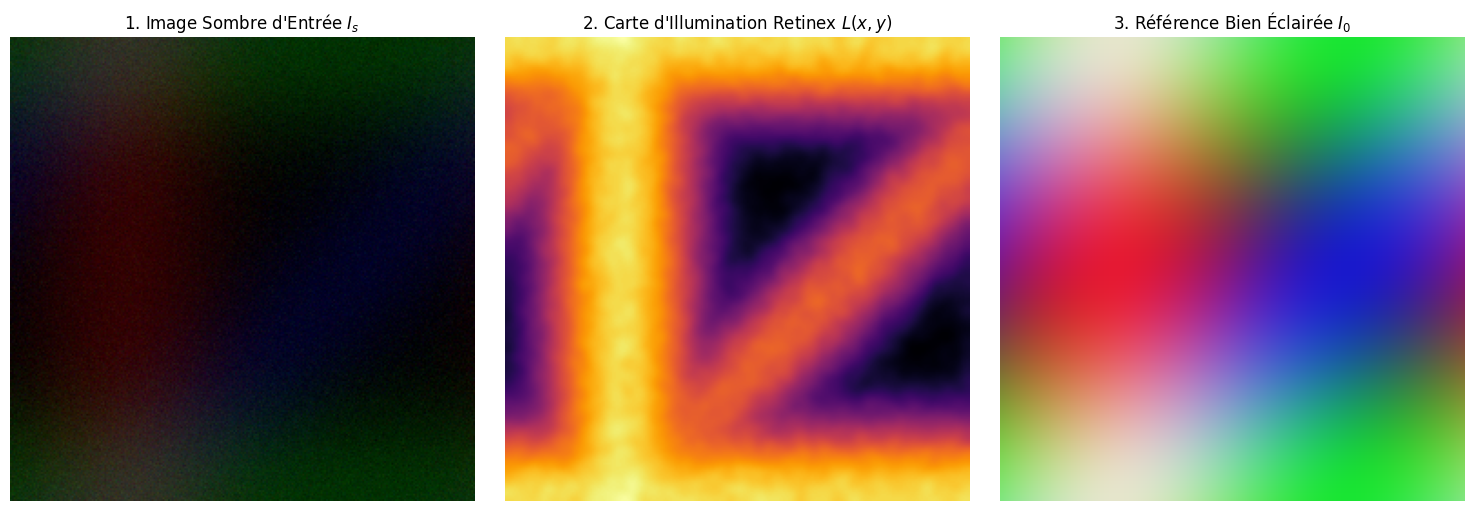

In [2]:
# Création d'un tenseur d'image sombre synthétique
ds = SyntheticPairDataset(length=2, image_size=256)
sample = ds[0]
low_img = sample["low_orig"].permute(1, 2, 0).numpy()
normal_img = sample["normal_orig"].permute(1, 2, 0).numpy()

# Estimation de l'illumination Retinex
estimator = RetinexEstimator(kernel_size=15, sigma=3.0, normalize=True)
illum_map = estimator.estimate_from_numpy(low_img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(low_img)
axes[0].set_title("1. Image Sombre d'Entrée $I_s$")
axes[0].axis("off")

axes[1].imshow(illum_map.squeeze(2), cmap="inferno")
axes[1].set_title("2. Carte d'Illumination Retinex $L(x,y)$")
axes[1].axis("off")

axes[2].imshow(normal_img)
axes[2].set_title("3. Référence Bien Éclairée $I_0$")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### 2. Découpage en Patchs 128 × 128 et Reconstruction

In [3]:
extractor = PatchExtractor(patch_size=128, stride_eval=64, blending_mode="hann")
tensor_in = sample["low_orig"]  # (3, 256, 256)

# Décomposition en patchs
patches, coords, orig_shape = extractor.decompose_image_for_eval(tensor_in)
print(f"Image originale : {orig_shape}")
print(f"Nombre de patchs extraits : {patches.shape[0]} de taille {patches.shape[1:]}")

# Reconstruction
reconstructed = extractor.reconstruct_image(patches, coords, orig_shape)
error = (tensor_in - reconstructed).abs().max().item()
print(f"Erreur maximale de reconstruction après fenêtrage : {error:.2e}")

Image originale : (256, 256)
Nombre de patchs extraits : 9 de taille torch.Size([3, 128, 128])
Erreur maximale de reconstruction après fenêtrage : 4.47e-08


### 3. Visualisation de la Grille de Patchs

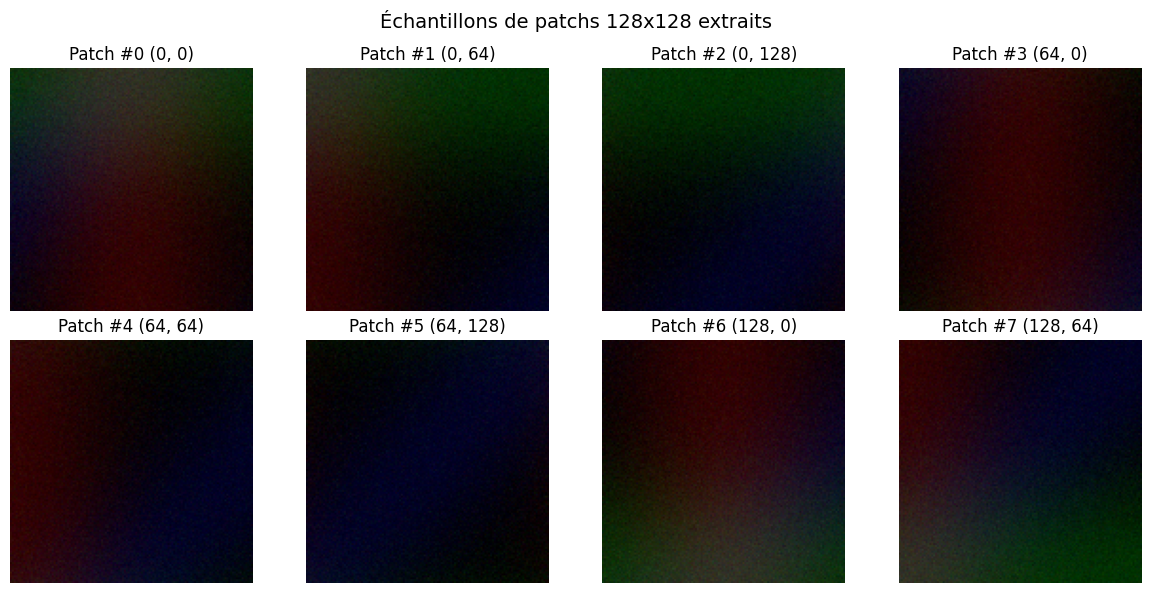

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, ax in enumerate(axes.flat):
    if idx < len(patches):
        patch_np = patches[idx].permute(1, 2, 0).numpy()
        ax.imshow(patch_np)
        ax.set_title(f"Patch #{idx} {coords[idx]}")
    ax.axis("off")
plt.suptitle("Échantillons de patchs 128x128 extraits", fontsize=14)
plt.tight_layout()
plt.show()

### 4. Bilan
Le pipeline de patchs 128x128 et les cartes d'illumination Retinex sont validés. Les patchs sont directement exploitables par les modèles A, B et C.